<div style="background-color:#B5121B;color:#ffffff;padding:16px 22px;border-radius:6px;font-family:Arial, Helvetica, sans-serif;">
<div style="font-size:12px;letter-spacing:0.08em;text-transform:uppercase;opacity:0.85;">PHYS7101 &middot; Numerical Methods and Data Analysis</div>
<div style="font-size:21px;font-weight:700;margin-top:6px;line-height:1.3;">Week 1 — Why Numerical Methods? Floating Point, Error & Complexity</div>
</div>

<div style="background-color:#38614A;color:#ffffff;padding:10px 16px;border-radius:4px;font-family:Arial, Helvetica, sans-serif;font-weight:700;margin-top:10px;">
Worked solutions: try each exercise yourself first, then compare.
</div>

#### This notebook introduces the computational foundations that sit underneath every numerical and statistical technique you'll use in this course. 
***

## <span style="color:#B5121B">1. Computers don't do algebra</span>

A computer doesn't manipulate symbols the way you do on paper. It does arithmetic on a finite-precision approximation of a real number, many times, very fast. That distinction sounds pedantic until you see it break.

In [1]:
print(0.1 + 0.2)
print(0.1 + 0.2 == 0.3)

0.30000000000000004
False


As in the lecture, `0.1` and `0.2` cannot be represented *exactly* in binary floating point (just as $1/3$ cannot be written exactly in decimal). Each is stored as the closest double-precision value, and the small representation errors don't cancel when you add them. This isn't a Python bug: it is IEEE 754 double precision, the standard used by almost every numerical language.

Floating-point addition is also not strictly associative:

In [2]:
a = 1e16
b = -1e16
c = 1.0

print((a + b) + c)   # cancel the two huge numbers first, then add the small one
print(a + (b + c))   # add the small number to a huge one first

1.0
0.0


Same three numbers, same `+`, different grouping, different answer. `b + c` rounds straight back to `b`, because `1.0` is too small to survive being added to $-10^{16}$ in double precision. The lesson isn't "avoid floating point". It is that **the order of operations in your code can change the answer.**

> **Quick check:** find a fourth number `d` such that `a + b + c + d` gives yet another answer depending on the grouping. (There is more than one way to do this.)
***

In [3]:
d = 1.0
print("((a + b) + c) + d =", ((a + b) + c) + d)
print("(a + (b + c)) + d =", (a + (b + c)) + d)
print("a + ((b + c) + d) =", a + ((b + c) + d))
print("a + (b + (c + d)) =", a + (b + (c + d)))

((a + b) + c) + d = 2.0
(a + (b + c)) + d = 1.0
a + ((b + c) + d) = 0.0
a + (b + (c + d)) = 2.0


<span style="color:#38614A">**Answer.**</span> With `d = 1.0`, changing only the brackets gives 2, 1 or 0. A 1 added directly to $\pm10^{16}$ is lost (the spacing between doubles there is 2), but `c + d = 2` survives. Any small `d` comparable to `c` works; a huge `d` swamps everything.

## <span style="color:#B5121B">2. Catastrophic cancellation: when a textbook-correct formula fails</span>

Suppose a detector logs the arrival time of every event, in seconds since the experiment started. After about 17 days the timestamps are around 1.5 million seconds, but what you care about is the *spread* (jitter) between events, which might be only a millisecond.

In [4]:
import numpy as np

rng = np.random.default_rng(7)
offset = 1.5e6          # seconds since experiment start (~17 days)
true_jitter_std = 1e-3  # true timing jitter: 1 millisecond

timestamps = offset + rng.normal(0, true_jitter_std, size=100_000)
print("first few timestamps:", timestamps[:3])
print("true variance (by construction):", true_jitter_std ** 2)

first few timestamps: [1500000.00000123 1500000.00029875 1499999.99972586]
true variance (by construction): 1e-06


The lecture introduced the sum-of-squares formula for the variance, $\mathrm{Var}(x) = E[x^2] - (E[x])^2$. Compute it that way and compare with NumPy's `np.var`:

In [5]:
naive_var = np.mean(timestamps**2) - np.mean(timestamps)**2
numpy_var = np.var(timestamps)

print(f"naive  E[x^2]-E[x]^2 : {naive_var: .6e}")
print(f"numpy  np.var(x)     : {numpy_var: .6e}")
print(f"true value           : {true_jitter_std**2: .6e}")

naive  E[x^2]-E[x]^2 : -4.882812e-04
numpy  np.var(x)     :  9.965963e-07
true value           :  1.000000e-06


**The naive formula gives a *negative* variance.** A variance is a sum of squares, so it is mathematically _impossible_ for it to be negative. When your result suggests an impossible number, your first thought should be that something in the *computation* is broken, not that the underlying physics is wrong.

Why? `timestamps**2` is around $(1.5\times10^6)^2 = 2.25\times10^{12}$, and double precision carries about 15–17 significant figures. The millisecond jitter sits about nine orders of magnitude below that. `E[x^2]` and `(E[x])^2` are two huge, nearly equal numbers: subtracting them removes all the useful digits and leaves rounding noise. This is the **catastrophic cancellation** from the lecture, and it is one of the most common ways scientific code silently gives the wrong answer.

`np.var` avoids this. It computes the mean first and then works with the deviations `x - mean(x)`, which are on the scale of the spread rather than the offset. Same quantity, same data, different order of operations.

### A stable, one-pass alternative: Welford's algorithm

If you can't call `np.var` (for example, if measurements arrive one at a time and you can't store them all), use Welford's algorithm (1962) from the lecture. It updates the mean and variance one value at a time and never squares the large numbers.

In [6]:
def welford_variance(data):
    n = 0
    mean = 0.0
    M2 = 0.0
    for x in data:
        n += 1
        delta = x - mean
        mean += delta / n
        delta2 = x - mean
        M2 += delta * delta2
    return M2 / n

welford_var = welford_variance(timestamps)
print(f"Welford's algorithm  : {welford_var: .6e}")
print(f"true value           : {true_jitter_std**2: .6e}")

Welford's algorithm  :  9.965964e-07
true value           :  1.000000e-06


This agrees with NumPy and with the true value to several significant figures. The formula on the page and the algorithm in your code are not the same thing.

> **Exercise:** try two or three `(offset, true_jitter_std)` combinations of your own, with offsets much larger and much smaller than $1.5\times10^6$. For each, note whether the naive formula gives a wrong but plausible number, exactly zero, or a negative number. Does `np.var` ever get it wrong? Can you find a combination where *even Welford's algorithm* struggles?
***

In [7]:
def compare(offset, jitter, n=100_000, seed=7):
    x = offset + np.random.default_rng(seed).normal(0, jitter, size=n)
    naive = np.mean(x**2) - np.mean(x)**2
    return naive, np.var(x), welford_variance(x), jitter**2

print(f"{'offset':>8} {'jitter':>8} | {'naive':>11} {'np.var':>11} {'Welford':>11} {'true':>11}")
for offset, jitter in [(1e3, 1e-3), (1.5e6, 1e-3), (1e8, 1e-3), (1e8, 1.0), (1e12, 1e-3), (1e14, 1e-3)]:
    naive, npv, wel, true = compare(offset, jitter)
    print(f"{offset:8.0e} {jitter:8.0e} | {naive: .3e} {npv: .3e} {wel: .3e} {true: .3e}")

for offset in [1.5e6, 1e8, 1e12, 1e14]:
    print(f"spacing of doubles near {offset:.0e}: {np.spacing(offset):.1e}")

  offset   jitter |       naive      np.var     Welford        true


   1e+03    1e-03 |  9.966e-07  9.966e-07  9.966e-07  1.000e-06
   2e+06    1e-03 | -4.883e-04  9.966e-07  9.966e-07  1.000e-06


   1e+08    1e-03 |  2.000e+00  9.966e-07  9.966e-07  1.000e-06


   1e+08    1e+00 |  0.000e+00  9.966e-01  9.966e-01  1.000e+00


   1e+12    1e-03 |  1.342e+08  9.980e-07  1.532e-06  1.000e-06


   1e+14    1e-03 |  0.000e+00  0.000e+00  0.000e+00  1.000e-06
spacing of doubles near 2e+06: 2.3e-10
spacing of doubles near 1e+08: 1.5e-08
spacing of doubles near 1e+12: 1.2e-04
spacing of doubles near 1e+14: 1.6e-02


<span style="color:#38614A">**Answer.**</span> From the table:

1. **Small offset** ($10^3$): all three methods agree with the true value.
2. **Moderate offsets** ($1.5\times10^6$, $10^8$): the naive formula gives a negative number, exactly zero, or a positive number wrong by orders of magnitude, depending on rounding (it changes with the seed). `np.var` and Welford are correct.
3. **Offset $10^{12}$, 1 ms jitter: Welford struggles** (about 50% too high with this seed) while `np.var` is still right. Welford's running mean is a number near $10^{12}$, and each update adds `delta / n` (~$10^{-3}/n$), which is smaller than the spacing between doubles there (~$10^{-4}$). The update is rounded away, as in the `1e16 + 1.0` example in Section 1, so the mean gets stuck and the variance picks up the square of its error. Over 30 seeds the error ranged from ~0 to ~50% (above 5% for about half), so students will see different numbers. `np.var` computes the mean once from the whole array (pairwise summation) and only then subtracts it.
4. **Offset $10^{14}$**: every method returns 0. The spacing of doubles (~$10^{-2}$) is ten times the jitter, so the stored timestamps are identical: the information was lost when the numbers were stored.

Lesson: store times relative to a nearby reference, and prefer library routines such as `np.var` to hand-written formulas.

## <span style="color:#555656">Aside: why this module is in Python</span>

Python trades execution speed for development speed. It is interpreted and dynamically typed, which is why vectorisation gave such a large speed-up in the revision notebook: it hands the work to compiled C code.

That trade-off is also why compiled or JIT-compiled languages (C++, Fortran, and increasingly Rust and Julia) still matter for large-scale physics simulations.
***

## <span style="color:#B5121B">3. Algorithmic complexity: how your code scales</span>

A related question: not "is the calculation correct?" but "how does its run time grow with the size of the dataset?" (the algorithmic complexity from the lecture). As an example, take a set of star positions and compute the sum of all pairwise distances.

In [8]:
import numpy as np

def naive_pairwise_distance_sum(points):
    """Sum of all pairwise distances - naive nested-loop version."""
    n = len(points)
    total = 0.0
    for i in range(n):
        for j in range(n):
            if i != j:
                dx = points[i, 0] - points[j, 0]
                dy = points[i, 1] - points[j, 1]
                total += np.sqrt(dx**2 + dy**2)
    return total

def vectorised_pairwise_distance_sum(points):
    """Same calculation, using NumPy broadcasting instead of Python loops."""
    diff = points[:, None, :] - points[None, :, :]
    dist = np.sqrt((diff**2).sum(axis=-1))
    return dist.sum()

# sanity check: both approaches should agree
rng = np.random.default_rng(0)
test_points = rng.uniform(0, 100, size=(50, 2))
a = naive_pairwise_distance_sum(test_points)
b = vectorised_pairwise_distance_sum(test_points)
print(f"naive result      : {a:.4f}")
print(f"vectorised result : {b:.4f}")
print(f"agree to within numerical precision: {np.isclose(a, b)}")

naive result      : 135134.4598
vectorised result : 135134.4598
agree to within numerical precision: True


In [9]:
import timeit

# Single timings are noisy (OS scheduling, caching, etc.) - take the minimum
# of several repeats for each n, which is the standard way to cut through that noise.
n_values = [50, 100, 200, 400, 800]
naive_times, vec_times = [], []

for n in n_values:
    points = rng.uniform(0, 100, size=(n, 2))

    tn = min(timeit.repeat(lambda: naive_pairwise_distance_sum(points), number=1, repeat=5))
    tv = min(timeit.repeat(lambda: vectorised_pairwise_distance_sum(points), number=1, repeat=5))

    naive_times.append(tn)
    vec_times.append(tv)
    print(f"n={n:4d}   naive={tn:8.4f}s   vectorised={tv:8.5f}s   ratio={tn/tv:6.1f}x")

n=  50   naive=  0.0029s   vectorised= 0.00009s   ratio=  30.4x


n= 100   naive=  0.0119s   vectorised= 0.00037s   ratio=  32.5x


n= 200   naive=  0.0487s   vectorised= 0.00214s   ratio=  22.8x


n= 400   naive=  0.1980s   vectorised= 0.00906s   ratio=  21.8x


n= 800   naive=  0.7987s   vectorised= 0.03180s   ratio=  25.1x


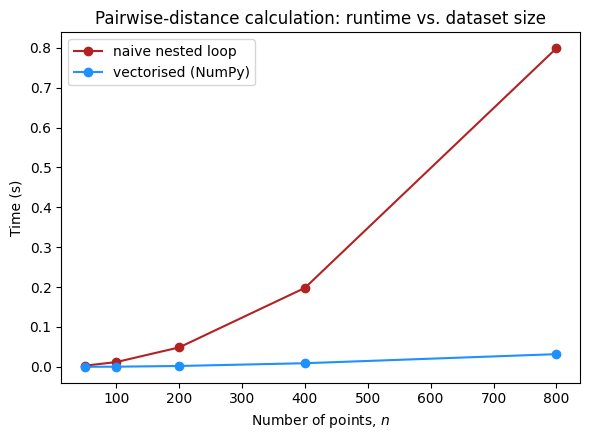

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(n_values, naive_times, "o-", color="firebrick", label="naive nested loop")
ax.plot(n_values, vec_times, "o-", color="dodgerblue", label="vectorised (NumPy)")
ax.set_xlabel("Number of points, $n$")
ax.set_ylabel("Time (s)")
ax.set_title("Pairwise-distance calculation: runtime vs. dataset size")
ax.legend()
fig.tight_layout()
plt.show()

The naive version grows roughly as $n^2$: doubling $n$ roughly quadruples the number of pairs, which is why the red curve rises so much more steeply than the blue one. The vectorised version scales much more gently over this range, because the work happens in compiled code operating on whole arrays. Datasets are now routinely thousands of rows long, and at that size the naive version becomes impractical.

> **Exercise:** add a third implementation using `scipy.spatial.distance.pdist` to the timing comparison and the plot. How does it compare with the vectorised version, and can you explain why?
***

agrees with vectorised: True


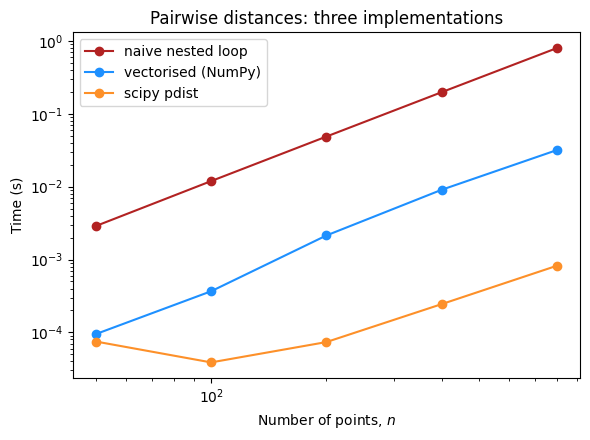

n=  50  vectorised=9.48e-05s  pdist=7.49e-05s  ratio=1.3x
n= 100  vectorised=3.67e-04s  pdist=3.87e-05s  ratio=9.5x
n= 200  vectorised=2.14e-03s  pdist=7.36e-05s  ratio=29.0x
n= 400  vectorised=9.06e-03s  pdist=2.44e-04s  ratio=37.1x
n= 800  vectorised=3.18e-02s  pdist=8.22e-04s  ratio=38.7x


In [11]:
from scipy.spatial.distance import pdist

def pdist_pairwise_distance_sum(points):
    # pdist returns each unordered pair once; the other two functions count both
    # (i, j) and (j, i), so double it to compare like with like.
    return 2 * pdist(points).sum()

print("agrees with vectorised:", np.isclose(pdist_pairwise_distance_sum(test_points),
                                            vectorised_pairwise_distance_sum(test_points)))

pdist_times = []
for n in n_values:
    points = rng.uniform(0, 100, size=(n, 2))
    pdist_times.append(min(timeit.repeat(lambda: pdist_pairwise_distance_sum(points), number=1, repeat=5)))

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.loglog(n_values, naive_times, "o-", color="firebrick", label="naive nested loop")
ax.loglog(n_values, vec_times, "o-", color="dodgerblue", label="vectorised (NumPy)")
ax.loglog(n_values, pdist_times, "o-", color="#FD9029", label="scipy pdist")
ax.set_xlabel("Number of points, $n$")
ax.set_ylabel("Time (s)")
ax.set_title("Pairwise distances: three implementations")
ax.legend()
fig.tight_layout()
plt.show()
for n, tv, tp in zip(n_values, vec_times, pdist_times):
    print(f"n={n:4d}  vectorised={tv:.2e}s  pdist={tp:.2e}s  ratio={tv/tp:.1f}x")

<span style="color:#38614A">**Answer.**</span> `pdist` is roughly 10–30× faster than the NumPy version once $n$ is a few hundred (machine dependent). All three are $O(n^2)$: on the log-log plot the lines have similar slopes and different offsets. Reasons: `pdist` computes each pair once and skips the diagonal, and it runs as a single compiled loop, whereas the broadcasting version builds and processes an $n\times n\times 2$ temporary array. For large $n$ that memory traffic dominates. A log-log plot is the right choice: a power law becomes a straight line.

## <span style="color:#FD9029">Independent exercise: nuclear binding energy</span>

The examples above were constructed. This one uses real published data. Work through it in your own time.

The mass of a nucleus is *less* than the total mass of its separate protons and neutrons. The missing mass, converted via $E=mc^2$, is the **binding energy** that holds the nucleus together. For a nuclide with $Z$ protons, $N$ neutrons (mass number $A = Z+N$) and measured atomic mass $M$:

$$BE = \left[Z \cdot m(^1\mathrm{H}) + N \cdot m_n - M\right] \times 931.494\ \mathrm{MeV/u}$$

The atomic mass of hydrogen-1 is used (rather than the proton mass) so that the electron masses approximately cancel. `isotope_masses.csv` gives $Z$, $N$, $A$ and the atomic mass (in u) for eight isotopes from deuterium to uranium, from NIST's Atomic Weights and Isotopic Compositions table.

In [12]:
import pandas as pd
import os

# Data: read from a local datasets/ folder if you've cloned/downloaded the
# repository, otherwise straight from GitHub (e.g. in Colab). Same file either way.
DATA_URL = "https://raw.githubusercontent.com/MatSmithAstro/phys7101_2026_resources/main/workshops/week1/datasets/"

def data_path(filename):
    local = os.path.join("datasets", filename)
    return local if os.path.exists(local) else DATA_URL + filename


m_H1 = 1.00782503223   # atomic mass of hydrogen-1, u (NIST)
m_n = 1.00866491606    # neutron mass, u (NIST CODATA)
u_to_MeV = 931.49410372  # 1 u in MeV (NIST CODATA)

isotopes = pd.read_csv(data_path("isotope_masses.csv"))
isotopes

,isotope,Z,N,A,atomic_mass_u,source
0,H-2 (deuteron),1,1,2,2.014102,NIST Atomic Weights and Isotopic Compositions
1,He-4 (alpha),2,2,4,4.002603,NIST Atomic Weights and Isotopic Compositions
2,C-12,6,6,12,12.000000,NIST Atomic Weights and Isotopic Compositions
3,O-16,8,8,16,15.994915,NIST Atomic Weights and Isotopic Compositions
4,Fe-56,26,30,56,55.934936,NIST Atomic Weights and Isotopic Compositions
5,Pb-208,82,126,208,207.976653,NIST Atomic Weights and Isotopic Compositions
6,U-235,92,143,235,235.043930,NIST Atomic Weights and Isotopic Compositions
7,U-238,92,146,238,238.050788,NIST Atomic Weights and Isotopic Compositions


**Part A.** Compute the binding energy per nucleon, $BE/A$, for each isotope in double precision (the default) and plot it against $A$. You should recover the nuclear binding energy curve, peaking around iron/nickel. This is why fusion releases energy for light elements and fission for heavy ones.

H-2 (deuteron)      A=     2   BE/A = 1.1123 MeV
He-4 (alpha)        A=     4   BE/A = 7.0739 MeV
C-12                A=    12   BE/A = 7.6801 MeV
O-16                A=    16   BE/A = 7.9762 MeV
Fe-56               A=    56   BE/A = 8.7903 MeV
Pb-208              A=   208   BE/A = 7.8675 MeV
U-235               A=   235   BE/A = 7.5909 MeV
U-238               A=   238   BE/A = 7.5701 MeV


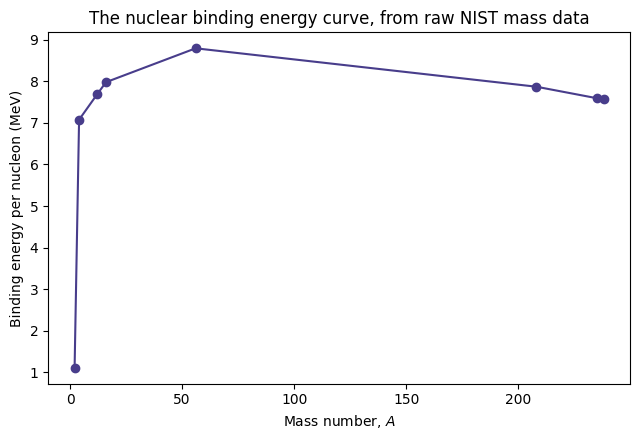

In [13]:
Z = isotopes["Z"].to_numpy(dtype=np.float64)
N = isotopes["N"].to_numpy(dtype=np.float64)
A = isotopes["A"].to_numpy(dtype=np.float64)
M = isotopes["atomic_mass_u"].to_numpy(dtype=np.float64)

BE = (Z * m_H1 + N * m_n - M) * u_to_MeV
BE_per_A = BE / A

for name, a_val, bea in zip(isotopes["isotope"], A, BE_per_A):
    print(f"{name:18s}  A={a_val:6.0f}   BE/A = {bea:.4f} MeV")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(A, BE_per_A, "o-", color="darkslateblue")
ax.set_xlabel("Mass number, $A$")
ax.set_ylabel("Binding energy per nucleon (MeV)")
ax.set_title("The nuclear binding energy curve, from raw NIST mass data")
fig.tight_layout()
plt.show()

**Part B.** Repeat the calculation with every mass cast to `np.float16` (half precision, about 3 significant figures). Plot both curves on the same axes. The masses go up to 238 and the physics is in the 4th–5th significant figure: what do you expect *before* you run it?

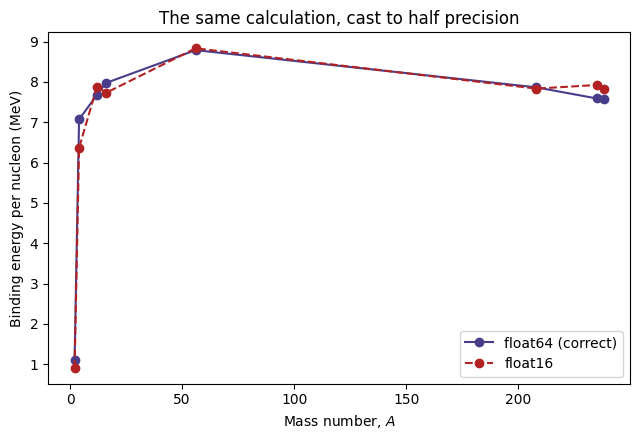

In [14]:
Z16 = isotopes["Z"].to_numpy(dtype=np.float16)
N16 = isotopes["N"].to_numpy(dtype=np.float16)
A16 = isotopes["A"].to_numpy(dtype=np.float16)
M16 = isotopes["atomic_mass_u"].to_numpy(dtype=np.float16)

BE16 = (Z16 * np.float16(m_H1) + N16 * np.float16(m_n) - M16) * np.float16(u_to_MeV)
BE_per_A16 = BE16 / A16

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(A, BE_per_A, "o-", color="darkslateblue", label="float64 (correct)")
ax.plot(A, BE_per_A16, "o--", color="firebrick", label="float16")
ax.set_xlabel("Mass number, $A$")
ax.set_ylabel("Binding energy per nucleon (MeV)")
ax.set_title("The same calculation, cast to half precision")
ax.legend()
fig.tight_layout()
plt.show()

**Part C (harder).** The float16 error does not grow smoothly with $A$. For each isotope, compute the *fractional mass defect*, $(Z\,m(^1\mathrm{H}) + N\,m_n - M) / M$: how small the difference is relative to the numbers being subtracted. Does it predict which isotopes have the worst float16 error? What does this tell you about when a precision choice that "should be fine" (238 fits easily in float16's range) isn't?

**Part D (reflection, no code).** In one or two sentences: if a nuclear-physics code computed binding energies in single precision (`float32`) rather than double, would you fix it? Use your results from Parts B and C to justify your answer.

In [15]:
Z32, N32, A32, M32 = (isotopes[c].to_numpy(dtype=np.float32) for c in ["Z", "N", "A", "atomic_mass_u"])
BE32 = (Z32 * np.float32(m_H1) + N32 * np.float32(m_n) - M32) * np.float32(u_to_MeV)
err32_keV = np.abs((BE32 / A32).astype(np.float64) - BE_per_A) * 1e3
for name, e, a in zip(isotopes["isotope"], err32_keV, A):
    print(f"{name:18s}  float32 error in BE/A: {e*1e3:6.1f} eV   in total BE: {e*a:6.2f} keV")

H-2 (deuteron)      float32 error in BE/A:   32.0 eV   in total BE:   0.06 keV
He-4 (alpha)        float32 error in BE/A:   62.6 eV   in total BE:   0.25 keV
C-12                float32 error in BE/A:   15.7 eV   in total BE:   0.19 keV
O-16                float32 error in BE/A:    6.8 eV   in total BE:   0.11 keV
Fe-56               float32 error in BE/A:   54.3 eV   in total BE:   3.04 keV
Pb-208              float32 error in BE/A:   46.9 eV   in total BE:   9.76 keV
U-235               float32 error in BE/A:    6.0 eV   in total BE:   1.42 keV
U-238               float32 error in BE/A:   46.3 eV   in total BE:  11.03 keV


<span style="color:#38614A">**Answer.**</span> In float32, $BE/A$ is off by at most a few tens of eV per nucleon, invisible on the ~8 MeV curve. But the *total* binding energy of the heavy nuclei is off by ~10 keV, because float32 can only represent a mass near 238 u to about $1.5\times10^{-5}$ u (14 keV), while the CSV gives the masses to $10^{-8}$ u or better. Anything that takes differences of binding energies (separation energies, Q-values) inherits keV-level errors. Verdict: fine for plotting the curve, worth fixing for anything quantitative. Accept either verdict if it is backed by numbers like these.

isotope            mass defect (u)  defect / M  float16 rel. error in BE/A
H-2 (deuteron)             0.00239    1.19e-03                       18.2%
He-4 (alpha)               0.03038    7.59e-03                       10.0%
C-12                       0.09894    8.24e-03                        2.7%
O-16                       0.13700    8.57e-03                        3.1%
Fe-56                      0.52846    9.45e-03                        0.5%
Pb-208                     1.75678    8.45e-03                        0.4%
U-235                      1.91506    8.15e-03                        4.4%
U-238                      1.93419    8.13e-03                        3.4%


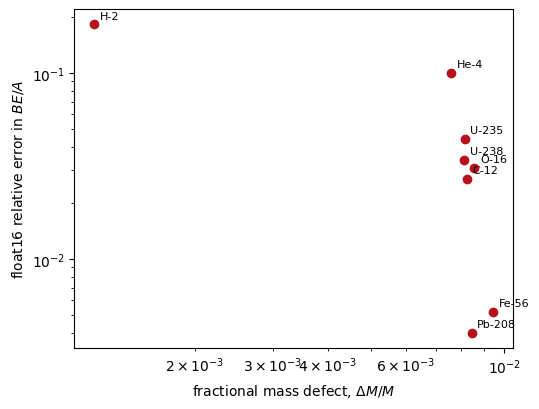

In [16]:
defect = Z * m_H1 + N * m_n - M
frac_defect = defect / M
rel_err16 = np.abs(BE_per_A16.astype(np.float64) - BE_per_A) / BE_per_A

print(f"{'isotope':18s} {'mass defect (u)':>15s} {'defect / M':>11s} {'float16 rel. error in BE/A':>27s}")
for name, dm, fd, e in zip(isotopes["isotope"], defect, frac_defect, rel_err16):
    print(f"{name:18s} {dm:15.5f} {fd:11.2e} {e:27.1%}")

fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.loglog(frac_defect, rel_err16, "o", color="#B5121B")
for name, x, y in zip(isotopes["isotope"], frac_defect, rel_err16):
    ax.annotate(name.split(" ")[0], (x, y), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.set_xlabel("fractional mass defect, $\\Delta M / M$")
ax.set_ylabel("float16 relative error in $BE/A$")
fig.tight_layout()
plt.show()

<span style="color:#38614A">**Answer.**</span> What matters is how small the *difference* is relative to the masses. float16 keeps about 3 significant figures (its spacing is 0.125 u near 200 and 0.03 u near 50), while the mass defect is only 0.1–1% of $M$, so the subtraction returns mostly rounding error. Deuterium (smallest fractional defect) is worst at ~18%; the heavy nuclei suffer because their absolute rounding is largest. The pattern isn't smooth in $A$ because it depends on where each mass falls on float16's grid. General lesson: fitting in a type's *range* says nothing about its *precision*. Compare the size of the answer relative to the numbers being subtracted with the type's relative precision ($\approx10^{-3}$ float16, $10^{-7}$ float32, $10^{-16}$ float64).

***
## Summary

Two lessons: 
1. A numerically "correct" formula can still be badly wrong in practice
2. The same calculation can scale very differently depending on how it's written 

<hr style="border:none;border-top:1px solid #BEC0C2;margin-top:32px;">
<div style="color:#555656;font-size:12px;margin-top:8px;font-family:Arial, Helvetica, sans-serif;">
PHYS7101 &mdash; Numerical Methods and Data Analysis
</div>